## Section 1 — Load data and inspect it

In [1]:
!pip -q install tensorflow scikit-learn seaborn

In [2]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

from google.colab import files
uploaded = files.upload()
csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_name is None:
    raise ValueError("Upload hotel_bookings.csv")
df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
print("Number of fields:", len(df.columns), "(assignment requires at least 15)")
assert len(df.columns) >= 15
display(df.head())
print("\nData types and non-null values:")
df.info()

Saving hotel_bookings (1).csv to hotel_bookings (1).csv
Dataset shape: (119390, 32)
Number of fields: 32 (assignment requires at least 15)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-nu

## Section 2 — Clean data and perform EDA

In [3]:
print("Missing values before cleaning (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicates and handle known missing values.
df = df.drop_duplicates().copy()
for col in ["children"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)
for col in ["country", "agent", "company"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown").astype(str)

# Create useful fields.
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# Basic validation and statistics.
if "adr" in df.columns:
    df = df[df["adr"].notna() & (df["adr"] >= 0)].copy()
print("Cleaned dataset shape:", df.shape)
display(df.describe(include="all").T.head(20))

# Outliers: report IQR counts; don't automatically remove plausible extreme bookings.
for col in ["lead_time", "adr", "total_nights"]:
    if col in df.columns:
        q1, q3 = df[col].quantile([.25, .75])
        iqr = q3-q1
        n = ((df[col] < q1-1.5*iqr) | (df[col] > q3+1.5*iqr)).sum()
        print(f"IQR outlier flags in {col}: {n}")

print("Cancellation rate (%):", round(df["is_canceled"].mean()*100, 2))

Missing values before cleaning (top 10):


,0
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


Duplicate rows: 31994
Cleaned dataset shape: (87395, 34)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,87395,2,City Hotel,53428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,87395.0,NaN,NaN,NaN,0.274901,0.446467,0.0,0.0,0.0,1.0,1.0
lead_time,87395.0,NaN,NaN,NaN,79.890051,86.051937,0.0,11.0,49.0,125.0,737.0
arrival_date_year,87395.0,NaN,NaN,NaN,2016.210287,0.686101,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,87395,12,August,11257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,87395.0,NaN,NaN,NaN,26.838526,13.674531,1.0,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87395.0,NaN,NaN,NaN,15.815665,8.835121,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87395.0,NaN,NaN,NaN,1.005229,1.031877,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,87395.0,NaN,NaN,NaN,2.625356,2.053564,0.0,1.0,2.0,4.0,50.0
adults,87395.0,NaN,NaN,NaN,1.875794,0.626504,0.0,2.0,2.0,2.0,55.0


IQR outlier flags in lead_time: 2396
IQR outlier flags in adr: 2490
IQR outlier flags in total_nights: 3014
Cancellation rate (%): 27.49


## Section 3 — Data Visualizations


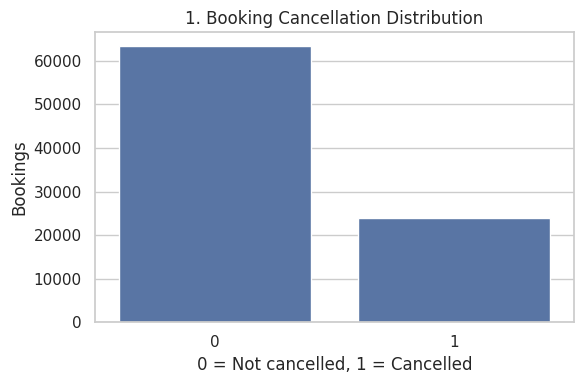

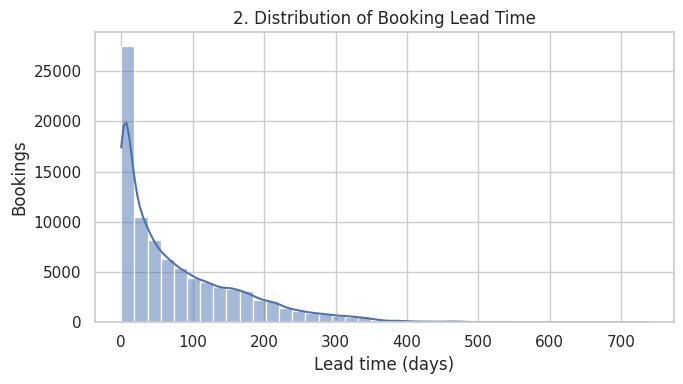

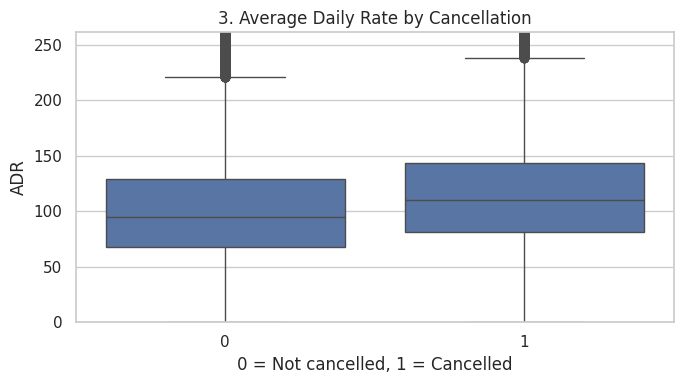

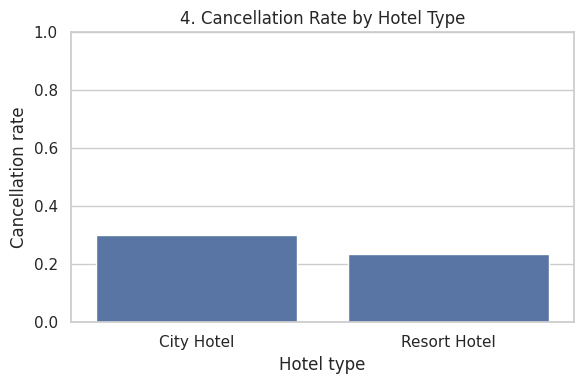

,cancellation_percent
hotel,
City Hotel,30.04
Resort Hotel,23.48


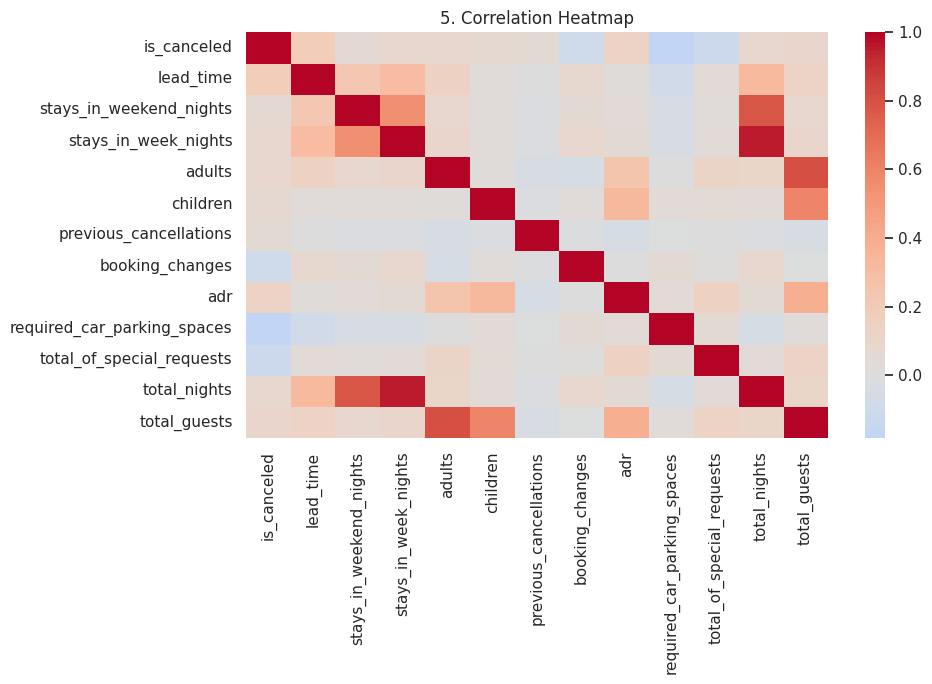

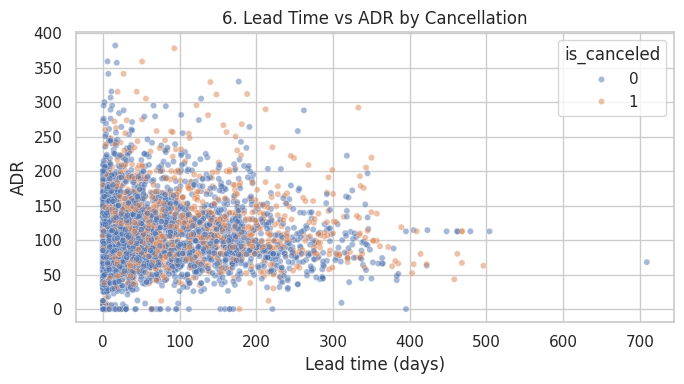

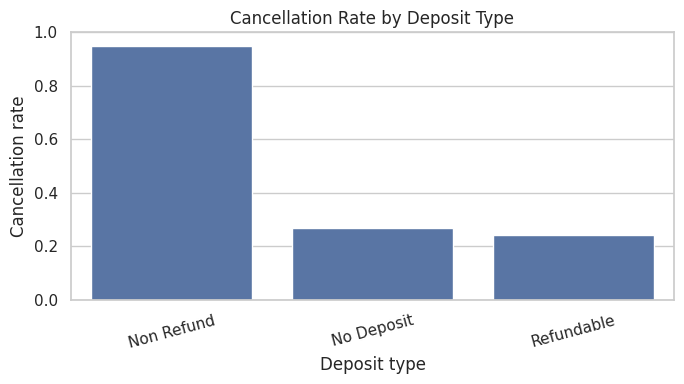

,cancellation_percent
deposit_type,
Non Refund,94.70
No Deposit,26.69
Refundable,24.30


In [4]:
os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")

# 1. Target distribution — shows class balance.
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="is_canceled")
plt.title("1. Booking Cancellation Distribution")
plt.xlabel("0 = Not cancelled, 1 = Cancelled"); plt.ylabel("Bookings")
plt.tight_layout(); plt.savefig("outputs/01_cancellation_distribution.png", dpi=150); plt.show()

# 2. Histogram — shows the distribution of booking lead time.
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="lead_time", bins=40, kde=True)
plt.title("2. Distribution of Booking Lead Time")
plt.xlabel("Lead time (days)"); plt.ylabel("Bookings")
plt.tight_layout(); plt.savefig("outputs/02_lead_time_histogram.png", dpi=150); plt.show()

# 3. Boxplot — compares ADR by cancellation status and flags possible outliers.
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="is_canceled", y="adr")
plt.ylim(0, df["adr"].quantile(.99))
plt.title("3. Average Daily Rate by Cancellation")
plt.xlabel("0 = Not cancelled, 1 = Cancelled"); plt.ylabel("ADR")
plt.tight_layout(); plt.savefig("outputs/03_adr_boxplot.png", dpi=150); plt.show()

# 4. Bar chart — compares cancellation rates by hotel type.
rates = df.groupby("hotel")["is_canceled"].mean().sort_values(ascending=False)
plt.figure(figsize=(6,4))
sns.barplot(x=rates.index, y=rates.values)
plt.title("4. Cancellation Rate by Hotel Type")
plt.xlabel("Hotel type"); plt.ylabel("Cancellation rate"); plt.ylim(0,1)
plt.tight_layout(); plt.savefig("outputs/04_hotel_cancellation_rate.png", dpi=150); plt.show()
display((rates*100).round(2).rename("cancellation_percent").to_frame())

# 5. Correlation heatmap — examines numerical relationships.
cols = [c for c in ["is_canceled","lead_time","stays_in_weekend_nights",
        "stays_in_week_nights","adults","children","previous_cancellations",
        "booking_changes","adr","required_car_parking_spaces",
        "total_of_special_requests","total_nights","total_guests"] if c in df.columns]
plt.figure(figsize=(10,7))
sns.heatmap(df[cols].corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("5. Correlation Heatmap")
plt.tight_layout(); plt.savefig("outputs/05_correlation_heatmap.png", dpi=150); plt.show()

# 6. Scatterplot — explores lead time vs ADR, coloured by cancellation.
sample = df.sample(min(4000, len(df)), random_state=42)
plt.figure(figsize=(7,4))
sns.scatterplot(data=sample, x="lead_time", y="adr", hue="is_canceled", alpha=.5, s=20)
plt.title("6. Lead Time vs ADR by Cancellation")
plt.xlabel("Lead time (days)"); plt.ylabel("ADR")
plt.tight_layout(); plt.savefig("outputs/06_lead_time_adr_scatter.png", dpi=150); plt.show()

# Extra distribution/bivariate analysis for rubric.
if "deposit_type" in df.columns:
    dep = df.groupby("deposit_type")["is_canceled"].mean().sort_values(ascending=False)
    plt.figure(figsize=(7,4))
    sns.barplot(x=dep.index, y=dep.values)
    plt.title("Cancellation Rate by Deposit Type"); plt.xlabel("Deposit type")
    plt.ylabel("Cancellation rate"); plt.ylim(0,1); plt.xticks(rotation=15)
    plt.tight_layout(); plt.savefig("outputs/07_deposit_type_cancellation.png", dpi=150); plt.show()
    display((dep*100).round(2).rename("cancellation_percent").to_frame())

## Section 4 — Preprocess data, split it, train and tune a Deep Learning model

In [5]:
# Prevent target leakage: exclude final status/date and the target itself.
X = df.drop(columns=["is_canceled", "reservation_status", "reservation_status_date"], errors="ignore")
y = df["is_canceled"].astype(int)

# Use 70% train, 15% validation, 15% test; stratify keeps class proportions similar.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=.15/.85, random_state=42, stratify=y_trainval)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)
])
X_train = prep.fit_transform(X_train).astype("float32")
X_val = prep.transform(X_val).astype("float32")
X_test = prep.transform(X_test).astype("float32")
print("Train, validation, test sizes:", len(y_train), len(y_val), len(y_test))

# Two simple configurations = basic hyperparameter tuning.
def build_model(units=64, lr=.001, dropout=.25):
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

configs = [{"units":64,"lr":.001,"dropout":.25},
           {"units":128,"lr":.001,"dropout":.30}]
models, histories, scores = [], [], []
for config in configs:
    model = build_model(**config)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    history = model.fit(X_train, y_train, validation_data=(X_val,y_val),
                        epochs=15, batch_size=256, callbacks=[stop], verbose=1)
    val_prob = model.predict(X_val, verbose=0).ravel()
    score = roc_auc_score(y_val, val_prob)
    models.append(model); histories.append(history); scores.append(score)
    print("Configuration:", config, "| validation ROC-AUC:", round(score,4))

best = int(np.argmax(scores))
model, history = models[best], histories[best]
print("Selected configuration:", configs[best])

Train, validation, test sizes: 61175 13110 13110
Epoch 1/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7887 - auc: 0.8286 - loss: 0.4388 - val_accuracy: 0.8207 - val_auc: 0.8842 - val_loss: 0.3715
Epoch 2/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8262 - auc: 0.8881 - loss: 0.3653 - val_accuracy: 0.8372 - val_auc: 0.9007 - val_loss: 0.3475
Epoch 3/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8374 - auc: 0.9001 - loss: 0.3468 - val_accuracy: 0.8406 - val_auc: 0.9057 - val_loss: 0.3383
Epoch 4/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8425 - auc: 0.9061 - loss: 0.3372 - val_accuracy: 0.8445 - val_auc: 0.9080 - val_loss: 0.3343
Epoch 5/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8477 - auc: 0.9104 - loss: 0.3300 - val_accuracy: 0.8481 - val_auc: 0.9112 - val_loss: 0.3278
Epoch 6/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8473 - auc: 0.9134 - loss: 0.3240 - val_accuracy: 0.8482 - val_auc: 0.9122 - val_lo

## Section 5 — Evaluation, feature importance and save outputs

Test metrics:
test_accuracy: 0.8436
test_precision: 0.7349
test_recall: 0.6740
test_f1: 0.7031
test_roc_auc: 0.9087
               precision    recall  f1-score   support

Not cancelled       0.88      0.91      0.89      9506
    Cancelled       0.73      0.67      0.70      3604

     accuracy                           0.84     13110
    macro avg       0.81      0.79      0.80     13110
 weighted avg       0.84      0.84      0.84     13110



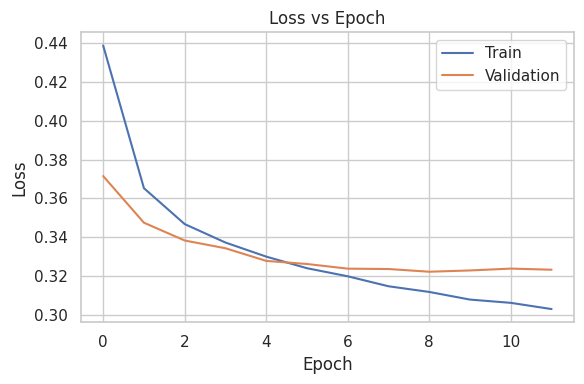

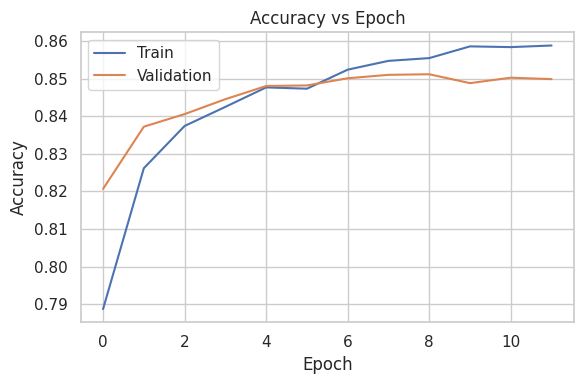

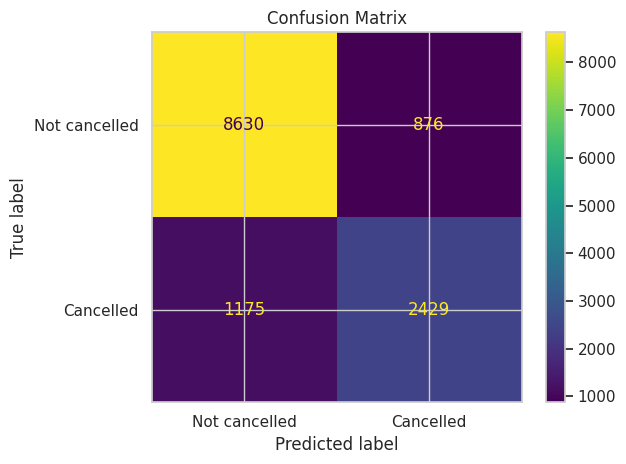

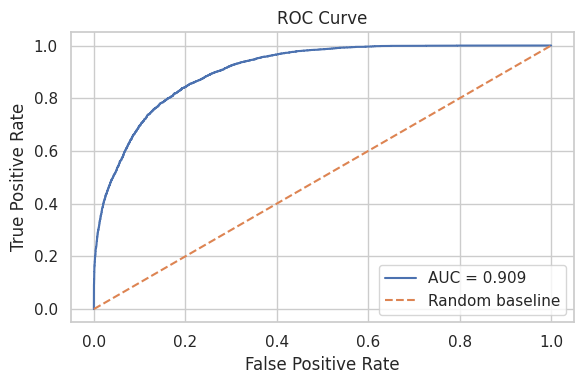

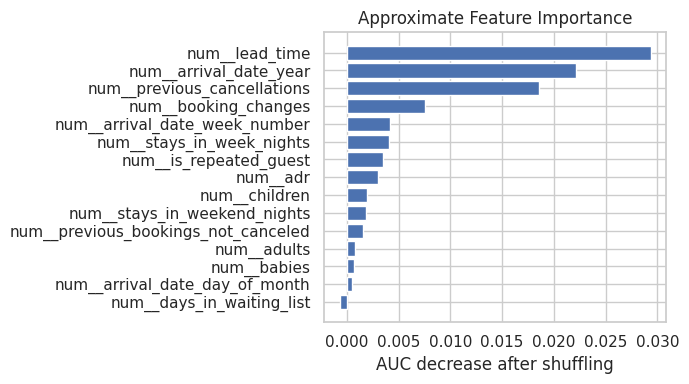

Saved charts, metrics and model in the outputs folder.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# Evaluate once on the held-out test set.
prob = model.predict(X_test, verbose=0).ravel()
pred = (prob >= .5).astype(int)
metrics = {
    "test_accuracy": accuracy_score(y_test,pred),
    "test_precision": precision_score(y_test,pred,zero_division=0),
    "test_recall": recall_score(y_test,pred,zero_division=0),
    "test_f1": f1_score(y_test,pred,zero_division=0),
    "test_roc_auc": roc_auc_score(y_test,prob)
}
print("Test metrics:")
for k,v in metrics.items(): print(f"{k}: {v:.4f}")
print(classification_report(y_test,pred,target_names=["Not cancelled","Cancelled"],zero_division=0))

# Evaluation visual 1: loss vs epoch.
plt.figure(figsize=(6,4))
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss vs Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/08_loss_vs_epoch.png",dpi=150); plt.show()

# Evaluation visual 2: accuracy vs epoch.
plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy vs Epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/09_accuracy_vs_epoch.png",dpi=150); plt.show()

# Evaluation visual 3: confusion matrix.
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["Not cancelled","Cancelled"],values_format="d")
plt.title("Confusion Matrix"); plt.tight_layout()
plt.savefig("outputs/10_confusion_matrix.png",dpi=150); plt.show()

# Evaluation visual 4: ROC curve and AUC.
fpr,tpr,_ = roc_curve(y_test,prob)
plt.figure(figsize=(6,4))
plt.plot(fpr,tpr,label=f"AUC = {metrics['test_roc_auc']:.3f}")
plt.plot([0,1],[0,1],"--",label="Random baseline")
plt.title("ROC Curve"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/11_roc_curve.png",dpi=150); plt.show()

# Approximate permutation importance for up to 15 encoded features.
feature_names = prep.get_feature_names_out()
rng = np.random.default_rng(42)
n = min(1500,len(X_test))
idx = rng.choice(len(X_test),n,replace=False)
base_auc = roc_auc_score(y_test.iloc[idx], model.predict(X_test[idx],verbose=0).ravel())
imp = []
for j in range(min(X_test.shape[1],15)):
    shuffled = X_test[idx].copy()
    shuffled[:,j] = rng.permutation(shuffled[:,j])
    auc = roc_auc_score(y_test.iloc[idx],model.predict(shuffled,verbose=0).ravel())
    imp.append((feature_names[j],base_auc-auc))
imp_df = pd.DataFrame(imp,columns=["feature","auc_drop"]).sort_values("auc_drop")
plt.figure(figsize=(7,4))
plt.barh(imp_df["feature"],imp_df["auc_drop"])
plt.title("Approximate Feature Importance"); plt.xlabel("AUC decrease after shuffling")
plt.tight_layout(); plt.savefig("outputs/12_feature_importance.png",dpi=150); plt.show()

# Save numeric results and trained model.
import json
with open("outputs/metrics.json","w") as f: json.dump(metrics,f,indent=2)
model.save("outputs/hotel_cancellation_mlp.keras")
print("Saved charts, metrics and model in the outputs folder.")

# Download all outputs in one ZIP.
import shutil
shutil.make_archive("hotel_booking_outputs","zip","outputs")
files.download("hotel_booking_outputs.zip")